# 02-13-26 New for Three Part Chart


## General Import Functions

In [1]:
import scanpy as sc
import pandas as pd
import scipy.stats as stats
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42
from matplotlib.backends.backend_pdf import PdfPages
import seaborn as sns
import anndata as an

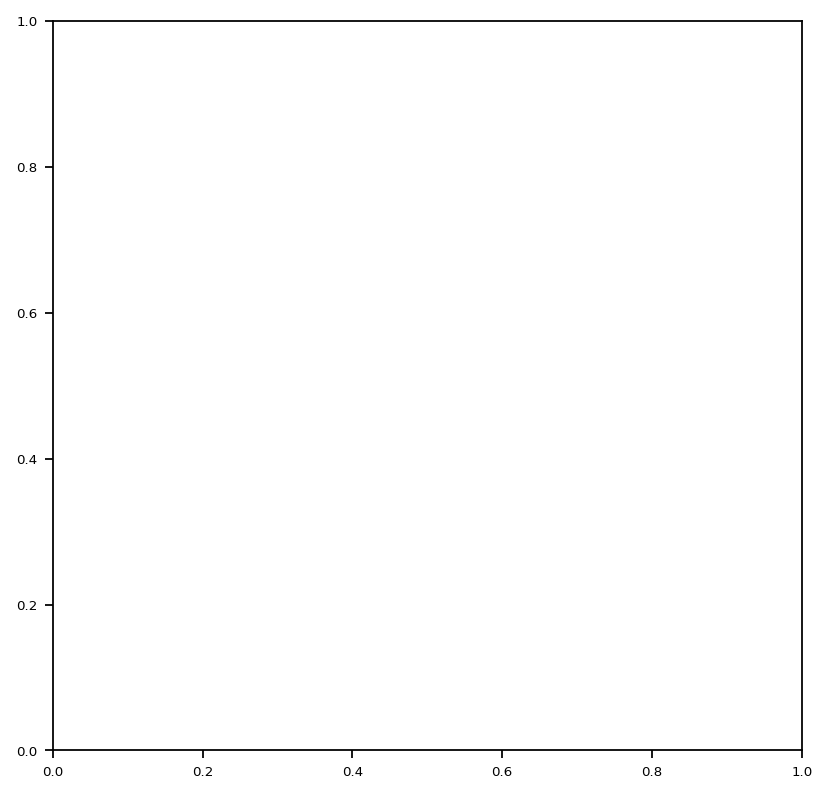

In [2]:
sc.settings.set_figure_params(dpi=80, dpi_save= 300, fontsize=6, 
                              facecolor='white', frameon=True, 
                              figsize=(3.0, 2.0), vector_friendly = False, 
                              transparent=True, format="pdf")

sns.set_style("ticks", rc = {'text.color' : "black",
                             'linecolor' : "black",
                             'axes.edgecolor' : "black",
                            'axes.labelcolor' : "black",
                            "xtick.color" : "black",
                            "ytick.color" : "black"})
fig, ax = plt.subplots(figsize = (6.0,6.0))

In [3]:
# 02-04-2026 added switch to save tau for all genes for work on external paper table.

DATA_IN_MEANS_DIR = '/oak/stanford/groups/quake/jonesbob/TF_TS_Analysis_Final_Manuscript/TFonly/'
DATA_IN_DIR = '/oak/stanford/groups/quake/jonesbob/TF_TS_Analysis_Final_Manuscript/'
DATA_OUT_DIR = '/oak/stanford/groups/quake/jonesbob/TF_TS_Analysis_Final_Manuscript/'  
META_DATA  = 'TSP1_30_version2d_10X_SS_2024_11_12_metadata_CLEAN_TFonly.csv'
COLOR_TABLE = 'CellTypeColorPalettes.csv'
TAU_TABLE = 'TauValuesCelltype.csv'
TFxCT_DATA = 'TSP1_30_by_CellType_Full_Version2d_Nov2024_LogNorm_10XOnly_Mean_TFonly.csv'



#DATA_IN_MEANS_DIR = '/oak/stanford/groups/quake/jonesbob/TF_TS_Analsyis_Working_Dir/AllGenes/'
#DATA_OUT_DIR = '/oak/stanford/groups/quake/jonesbob/TF_TS_Analsyis_Working_Dir/AllGenes/'  
#TAU_TABLE = 'TauValuesCelltypeALLGENES.csv'
#TFxCT_DATA = 'TSP1_30_by_CellType_Full_Version2d_Nov2024_LogNorm_10XOnly_Mean_AllGenes.csv'

In [4]:
# Now read in mean
print(DATA_IN_MEANS_DIR+TFxCT_DATA)
TF_df = pd.read_csv(DATA_IN_MEANS_DIR+TFxCT_DATA, index_col = 0)
TF_df.shape

/oak/stanford/groups/quake/jonesbob/TF_TS_Analysis_Final_Manuscript/TFonly/TSP1_30_by_CellType_Full_Version2d_Nov2024_LogNorm_10XOnly_Mean_TFonly.csv


(175, 1637)

In [5]:
# remove zeros and sort for looks
TF_exp_all = TF_df.T
TF_exp = TF_exp_all[TF_exp_all.sum(axis = 1) != 0.0]
TF_exp = TF_exp.sort_index(axis=0).sort_index(axis=1)
TF_exp

,acinar_cell,acinar_cell_of_salivary_gland,activated_cd4_positive__alpha_beta_t_cell,activated_cd8_positive__alpha_beta_t_cell,adventitial_cell,alveolar_type_2_fibroblast_cell,b_cell,basal_cell,basal_cell_of_prostate_epithelium,basophil,...,transit_amplifying_cell_of_small_intestine,tuft_cell_of_colon,type_b_pancreatic_cell,type_i_pneumocyte,type_ii_pneumocyte,type_l_enteroendocrine_cell,vascular_associated_smooth_muscle_cell,vein_endothelial_cell,ventricular_cardiac_muscle_cell,vestibular_dark_cell
ADNP,0.046193,0.333551,0.513674,0.626556,0.378455,0.465089,0.608835,0.655836,0.763171,0.359936,...,0.492757,0.417895,0.340732,0.625163,0.450006,0.716034,0.447129,0.447148,0.427005,0.651063
ADNP2,0.009876,0.140091,0.325864,0.321171,0.193175,0.238748,0.161301,0.242889,0.258735,0.153731,...,0.317310,0.056905,0.075665,0.222563,0.266650,0.303473,0.338442,0.215884,0.161118,0.353341
AEBP1,0.006193,0.004961,0.002443,0.000000,1.288871,0.897549,0.034027,0.036436,0.011981,0.028147,...,0.000000,0.000000,0.000836,0.005759,0.000282,0.000000,0.489091,0.062086,0.226796,0.030797
AEBP2,0.044363,0.449820,0.424162,0.436206,0.402605,0.664268,0.411909,0.595855,0.641190,0.380733,...,0.160975,0.388699,0.353021,0.259166,0.384250,0.363918,0.456358,0.373508,0.266055,0.536432
AHCTF1,0.019100,0.169921,0.315120,0.399694,0.438465,0.657056,0.378615,0.370374,0.298039,0.209078,...,0.268948,0.177442,0.186194,0.352844,0.242891,0.372240,0.448918,0.450153,0.166566,0.512690
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
ZUP1,0.013551,0.043735,0.103288,0.139597,0.052359,0.032110,0.101960,0.092021,0.068077,0.063663,...,0.114799,0.089140,0.068827,0.084671,0.058728,0.079277,0.069017,0.087533,0.072503,0.140442
ZXDA,0.003665,0.007353,0.017801,0.020734,0.025428,0.022213,0.023666,0.017546,0.043380,0.020668,...,0.000000,0.008480,0.012849,0.019685,0.015708,0.036805,0.013482,0.025795,0.012939,0.038980
ZXDB,0.005427,0.018930,0.023318,0.017984,0.019682,0.026839,0.028418,0.031522,0.055306,0.013583,...,0.000000,0.033494,0.029991,0.041763,0.029279,0.025711,0.022962,0.036770,0.026582,0.050892
ZXDC,0.016650,0.226819,0.277453,0.276433,0.268865,0.330379,0.272625,0.324864,0.456630,0.233024,...,0.271677,0.181578,0.198911,0.486634,0.384730,0.276657,0.189008,0.284826,0.178414,0.209109


In [6]:
# just a check
#TF_exp.loc['GLI4', :].sort_values()

In [7]:

####################################################################
# Compute tau specificity value for each TF
####################################################################
tau_values = pd.Series( index = TF_exp.index)
for gene in TF_exp.index:
    genevector = TF_exp.loc[gene]
    normed = genevector/max(genevector)
    oneminus = 1 - normed
    tau_values.loc[gene] = sum(oneminus) / (len(oneminus) - 1)
tau_values = tau_values.sort_values(ascending=False)

print('Tau Max', tau_values.max())
print('Tau Min', tau_values.min())

Tau_Values = pd.DataFrame(tau_values)
Tau_Values.columns = ['tau']
print(DATA_OUT_DIR+TAU_TABLE)
#Tau_Values.to_csv(DATA_OUT_DIR+TAU_TABLE)
Tau_Values

Tau Max 0.9998679483524583
Tau Min 0.40006999898542256
/oak/stanford/groups/quake/jonesbob/TF_TS_Analysis_Final_Manuscript/TauValuesCelltype.csv


,tau
FOXD4L4,0.999868
FIGLA,0.999667
GSX2,0.999634
NEUROG1,0.999582
HOXC12,0.999473
...,...
ZNF644,0.459571
ASH1L,0.450371
YY1,0.434433
BPTF,0.432127


In [8]:
Tau_Values.iloc[  -30 : , :]

,tau
BAZ2B,0.539685
TCF12,0.538989
GLYR1,0.532532
EEA1,0.532179
FOXJ3,0.532092
ZFX,0.528017
GPBP1,0.527563
KDM2A,0.525825
USF3,0.520908
NFX1,0.515940


In [9]:
########## end of tau code #######

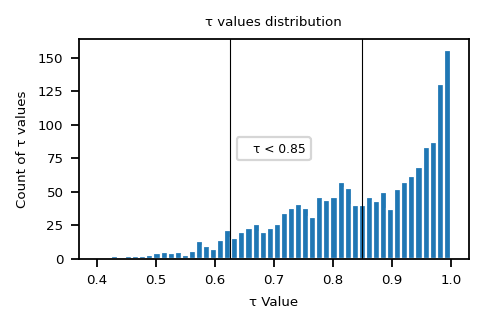

In [10]:
# distribution of Tau values has two peaks divided at 0.85 ???
# could add quantile normalization per Doug. Could argue ubiquitous is 0.54 and below.

from matplotlib.lines import Line2D

plt.hist(tau_values, bins=50)
plt.axvline(x=0.85, color='black', linestyle='-', linewidth=0.5)
plt.axvline(x=0.625831, color='black', linestyle='-', linewidth=0.5)

# Custom legend entry without a line
custom_legend = [Line2D([0], [0], linestyle='None', color='black', label='τ < 0.85')]

plt.xlabel("τ Value")
plt.ylabel("Count of τ values")
plt.title("τ values distribution")

plt.legend(handles=custom_legend, loc='center')
plt.tight_layout()
plt.savefig(DATA_OUT_DIR + 'SuppFig9A_Tau_Distribution_V2.pdf')
plt.show()

TGIF2LY      3
TGIF2LX      4
FOXB2        6
NEUROD6      6
FERD3L       7
          ... 
ZBTB20     175
NR2C1      175
ASH1L      175
ATF2       175
SMYD3      175
Length: 1635, dtype: int64

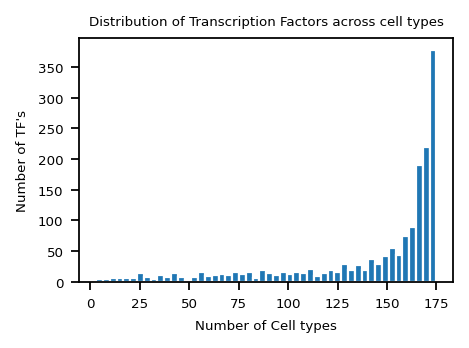

In [11]:
# look at Tf's in cell types 
TF_ctcount =  TF_exp.astype(bool).sum(axis=1).sort_values(ascending = True)
plt.hist(TF_ctcount, bins = 50)
plt.xlabel("Number of Cell types")
plt.ylabel("Number of TF's")
plt.title('Distribution of Transcription Factors across cell types')
TF_ctcount

## Only high tau or low tau

In [12]:
# break between ubiquitous and specific at 0.85 tau
# reconsider this after quantile normalization

low_tau = list(tau_values.index[tau_values <= 0.85])
hi_tau = list(tau_values.index[tau_values > 0.85])
TF_hi_exp = TF_exp.loc[hi_tau].copy()
TF_low_exp = TF_exp.loc[low_tau].copy()
print(len(TF_low_exp))
print(len((TF_hi_exp)))
print(len((TF_exp)))

745
890
1635


In [13]:
#Look distribution of zinc finger TF's only


In [14]:
# save list of lowest 100 for figure
low100 = tau_values.sort_values(ascending = True).iloc[0:100]
low100df = pd.DataFrame(low100)
#low100df.to_csv(DATA_OUT_DIR+'LowestTauTFs100.csv')
low100df

,0
SON,0.400070
BPTF,0.432127
YY1,0.434433
ASH1L,0.450371
ZNF644,0.459571
...,...
ZNF706,0.622885
ZNF44,0.624005
MTERF4,0.624207
KLF3,0.625298


## Now Make Heatmap. #####

In [15]:
# read metadata that goes with the full objects
metadata = pd.read_csv(DATA_IN_MEANS_DIR+META_DATA)
print(DATA_IN_MEANS_DIR+META_DATA)
metadata = metadata[metadata.method == '10X']
print(len(metadata.cell_ontology_class.unique()))
metadata

/tmp/ipykernel_11073/4150171882.py:2: DtypeWarning: Columns (8) have mixed types. Specify dtype option on import or set low_memory=False.
  metadata = pd.read_csv(DATA_IN_MEANS_DIR+META_DATA)


/oak/stanford/groups/quake/jonesbob/TF_TS_Analysis_Final_Manuscript/TFonly/TSP1_30_version2d_10X_SS_2024_11_12_metadata_CLEAN_TFonly.csv
175


,Unnamed: 0.1,Unnamed: 0,donor,tissue,anatomical_position,method,cdna_plate,library_plate,notes,cdna_well,...,pct_counts_mt,total_counts_ercc,pct_counts_ercc,_scvi_batch,_scvi_labels,scvi_leiden_donorassay_full,age,sex,ethnicity,sample_number
0,43170,TSP27_FAT_MAT_10X3primev31_1_1_AAACGAAGTTGAAGTA,TSP27,Fat,MAT,10X,NaN,NaN,NaN,NaN,...,4.557311,0.0,0.0,39,0,4,56,female,Hispanic,1
1,43171,TSP27_FAT_MAT_10X3primev31_1_1_AAAGTCCAGAGAGCGG,TSP27,Fat,MAT,10X,NaN,NaN,NaN,NaN,...,3.118908,0.0,0.0,39,0,56,56,female,Hispanic,1
2,43172,TSP27_FAT_MAT_10X3primev31_1_1_AAAGTGAAGCTCGACC,TSP27,Fat,MAT,10X,NaN,NaN,NaN,NaN,...,2.077456,0.0,0.0,39,0,56,56,female,Hispanic,1
3,43173,TSP27_FAT_MAT_10X3primev31_1_1_AACACACGTATGTCTG,TSP27,Fat,MAT,10X,NaN,NaN,NaN,NaN,...,3.426092,0.0,0.0,39,0,56,56,female,Hispanic,1
4,43174,TSP27_FAT_MAT_10X3primev31_1_1_AACCTTTAGAGTAACT,TSP27,Fat,MAT,10X,NaN,NaN,NaN,NaN,...,12.513543,0.0,0.0,39,0,26,56,female,Hispanic,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1093043,1136213,TSP25_FAT_Brown_10X_1_6_TTTGTTGCAAAGCACG,TSP25,Fat,Brown,10X,NaN,NaN,NaN,NaN,...,8.161605,0.0,0.0,36,0,2,60,male,Asian,1
1093044,1136214,TSP25_FAT_Brown_10X_1_6_TTTGTTGGTAAGTCAA,TSP25,Fat,Brown,10X,NaN,NaN,NaN,NaN,...,10.695262,0.0,0.0,36,0,2,60,male,Asian,1
1093045,1136215,TSP25_FAT_Brown_10X_1_6_TTTGTTGGTATACCCA,TSP25,Fat,Brown,10X,NaN,NaN,NaN,NaN,...,9.348170,0.0,0.0,36,0,0,60,male,Asian,1
1093046,1136216,TSP25_FAT_Brown_10X_1_6_TTTGTTGGTGTGTCCG,TSP25,Fat,Brown,10X,NaN,NaN,NaN,NaN,...,18.486906,0.0,0.0,36,0,2,60,male,Asian,1


In [16]:
def PrepColorTable(exp_matrix):

    # map broad cell types to celltypes for those types in exp_matrix
    ct = pd.DataFrame()
    ct['ctypes'] = metadata.cell_ontology_class
    print('length of cell types', len(ct))
    ct['comparts'] = metadata.compartment
    ct['broadct'] = metadata.broad_cell_class
    print('length of cell types', len(ct))
    #display(ct)     #one difference here is the ctype names don't have '_' 
    
    ct = ct[ct.ctypes.isin(exp_matrix.columns)]
    ct = ct.drop_duplicates('ctypes')
    print('length of cell types', len(ct))
    newindex = list(ct.ctypes)
    ct.index = newindex
    
    # map colors to the broad cell types
    colorlist = [matplotlib.colors.to_hex(c) for c in plt.cm.tab20.colors] + [matplotlib.colors.to_hex(c) for c in plt.cm.tab20b.colors]
    type_to_comp_dict = dict(zip(ct.broadct.unique(), colorlist))
    ct['col_colors'] = ct.broadct.map(type_to_comp_dict)

    return(ct)

In [17]:
TF_exp

,acinar_cell,acinar_cell_of_salivary_gland,activated_cd4_positive__alpha_beta_t_cell,activated_cd8_positive__alpha_beta_t_cell,adventitial_cell,alveolar_type_2_fibroblast_cell,b_cell,basal_cell,basal_cell_of_prostate_epithelium,basophil,...,transit_amplifying_cell_of_small_intestine,tuft_cell_of_colon,type_b_pancreatic_cell,type_i_pneumocyte,type_ii_pneumocyte,type_l_enteroendocrine_cell,vascular_associated_smooth_muscle_cell,vein_endothelial_cell,ventricular_cardiac_muscle_cell,vestibular_dark_cell
ADNP,0.046193,0.333551,0.513674,0.626556,0.378455,0.465089,0.608835,0.655836,0.763171,0.359936,...,0.492757,0.417895,0.340732,0.625163,0.450006,0.716034,0.447129,0.447148,0.427005,0.651063
ADNP2,0.009876,0.140091,0.325864,0.321171,0.193175,0.238748,0.161301,0.242889,0.258735,0.153731,...,0.317310,0.056905,0.075665,0.222563,0.266650,0.303473,0.338442,0.215884,0.161118,0.353341
AEBP1,0.006193,0.004961,0.002443,0.000000,1.288871,0.897549,0.034027,0.036436,0.011981,0.028147,...,0.000000,0.000000,0.000836,0.005759,0.000282,0.000000,0.489091,0.062086,0.226796,0.030797
AEBP2,0.044363,0.449820,0.424162,0.436206,0.402605,0.664268,0.411909,0.595855,0.641190,0.380733,...,0.160975,0.388699,0.353021,0.259166,0.384250,0.363918,0.456358,0.373508,0.266055,0.536432
AHCTF1,0.019100,0.169921,0.315120,0.399694,0.438465,0.657056,0.378615,0.370374,0.298039,0.209078,...,0.268948,0.177442,0.186194,0.352844,0.242891,0.372240,0.448918,0.450153,0.166566,0.512690
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
ZUP1,0.013551,0.043735,0.103288,0.139597,0.052359,0.032110,0.101960,0.092021,0.068077,0.063663,...,0.114799,0.089140,0.068827,0.084671,0.058728,0.079277,0.069017,0.087533,0.072503,0.140442
ZXDA,0.003665,0.007353,0.017801,0.020734,0.025428,0.022213,0.023666,0.017546,0.043380,0.020668,...,0.000000,0.008480,0.012849,0.019685,0.015708,0.036805,0.013482,0.025795,0.012939,0.038980
ZXDB,0.005427,0.018930,0.023318,0.017984,0.019682,0.026839,0.028418,0.031522,0.055306,0.013583,...,0.000000,0.033494,0.029991,0.041763,0.029279,0.025711,0.022962,0.036770,0.026582,0.050892
ZXDC,0.016650,0.226819,0.277453,0.276433,0.268865,0.330379,0.272625,0.324864,0.456630,0.233024,...,0.271677,0.181578,0.198911,0.486634,0.384730,0.276657,0.189008,0.284826,0.178414,0.209109


In [18]:
TFcolors = PrepColorTable(TF_exp)
print('TF_exp', TF_exp.shape)
#TFcolors.to_csv(DATA_IN_DIR+COLOR_TABLE)
display(TFcolors)
ct_order = TFcolors.sort_values('broadct').index 
TFcolors = TFcolors.loc[ct_order]
TFcolors

length of cell types 1093048
length of cell types 1093048
length of cell types 175
TF_exp (1635, 175)


,ctypes,comparts,broadct,col_colors
macrophage,macrophage,Immune,myeloid_leukocyte,#1f77b4
mesenchymal_stem_cell_of_adipose_tissue,mesenchymal_stem_cell_of_adipose_tissue,Stromal,stem_cell,#aec7e8
mast_cell,mast_cell,Immune,granulocyte,#ff7f0e
neutrophil,neutrophil,Immune,granulocyte,#ff7f0e
fibroblast,fibroblast,Stromal,fibroblast,#ffbb78
...,...,...,...,...
kidney_epithelial_cell,kidney_epithelial_cell,Epithelium,kidney_epithelial_cell,#7b4173
retinal_pigment_epithelial_cell,retinal_pigment_epithelial_cell,Epithelium,retinal_pigment_epithelial_cell,#a55194
keratinocyte,keratinocyte,Epithelium,epithelial_cell,#7f7f7f
enterocyte_of_epithelium_proper_of_jejunum,enterocyte_of_epithelium_proper_of_jejunum,Epithelium,intestinal_epithelial_cell,#bcbd22


,ctypes,comparts,broadct,col_colors
adventitial_cell,adventitial_cell,Stromal,adventitial_cell,#b5cf6b
cardiac_endothelial_cell,cardiac_endothelial_cell,Endothelium,cardiac_endothelial_cell,#393b79
ciliated_epithelial_cell,ciliated_epithelial_cell,Epithelium,ciliated_epithelial_cell,#e377c2
lung_ciliated_cell,lung_ciliated_cell,Epithelium,ciliated_epithelial_cell,#e377c2
ciliated_columnar_cell_of_tracheobronchial_tree,ciliated_columnar_cell_of_tracheobronchial_tree,Epithelium,ciliated_epithelial_cell,#e377c2
...,...,...,...,...
gamma_delta_t_cell,gamma_delta_t_cell,Immune,t_cell,#2ca02c
mature_nk_t_cell,mature_nk_t_cell,Immune,t_cell,#2ca02c
t_cell,t_cell,Immune,t_cell,#2ca02c
bladder_urothelial_cell,bladder_urothelial_cell,Epithelium,transitional_epithelial_cell,#17becf


In [19]:
ed = TF_exp.T

plot_data = ed.loc[ct_order].T
expr_data_plot = ed.loc[ct_order].T
expr_data_plot  # now the cell types are in order

,adventitial_cell,cardiac_endothelial_cell,ciliated_epithelial_cell,lung_ciliated_cell,ciliated_columnar_cell_of_tracheobronchial_tree,conjunctival_epithelial_cell,connective_tissue_cell,bronchial_smooth_muscle_cell,myometrial_cell,tongue_muscle_cell,...,regulatory_t_cell,naive_thymus_derived_cd8_positive__alpha_beta_t_cell,naive_thymus_derived_cd4_positive__alpha_beta_t_cell,activated_cd4_positive__alpha_beta_t_cell,activated_cd8_positive__alpha_beta_t_cell,gamma_delta_t_cell,mature_nk_t_cell,t_cell,bladder_urothelial_cell,vestibular_dark_cell
ADNP,0.378455,0.462867,0.466266,0.529221,0.565514,0.497125,0.488275,0.269635,0.479047,0.332385,...,0.443370,0.658961,0.467374,0.513674,0.626556,0.744589,0.632596,0.563665,0.488158,0.651063
ADNP2,0.193175,0.149852,0.211501,0.156244,0.131142,0.302681,0.131193,0.209486,0.319167,0.153276,...,0.178770,0.273635,0.208490,0.325864,0.321171,0.306895,0.198538,0.261537,0.372773,0.353341
AEBP1,1.288871,0.058844,0.000000,0.001837,0.008622,0.018560,1.058246,1.150609,0.397098,0.095480,...,0.012474,0.024131,0.027610,0.002443,0.000000,0.001482,0.012821,0.009060,0.000738,0.030797
AEBP2,0.402605,0.432417,0.541366,0.704556,0.884250,0.623117,0.344961,0.379561,0.417306,0.524837,...,0.431999,0.590181,0.420558,0.424162,0.436206,0.426247,0.464831,0.512912,0.470515,0.536432
AHCTF1,0.438465,0.341739,0.384281,0.263855,0.315227,0.403961,0.410665,0.281830,0.603726,0.450289,...,0.372696,0.497781,0.380999,0.315120,0.399694,0.502197,0.349160,0.421997,0.243048,0.512690
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
ZUP1,0.052359,0.085695,0.064653,0.038909,0.044723,0.126376,0.082521,0.014417,0.081262,0.039798,...,0.104643,0.094121,0.075943,0.103288,0.139597,0.151083,0.103678,0.091516,0.088299,0.140442
ZXDA,0.025428,0.041596,0.016440,0.016072,0.007156,0.017882,0.011403,0.011148,0.021780,0.013748,...,0.025152,0.018684,0.023089,0.017801,0.020734,0.011486,0.015217,0.018603,0.030345,0.038980
ZXDB,0.019682,0.025298,0.034957,0.021111,0.014792,0.072183,0.048877,0.022416,0.060519,0.006791,...,0.030548,0.025371,0.031387,0.023318,0.017984,0.022325,0.021566,0.024238,0.092115,0.050892
ZXDC,0.268865,0.233248,0.253357,0.341233,0.357332,0.174508,0.283933,0.188956,0.238220,0.322207,...,0.238636,0.352388,0.283431,0.277453,0.276433,0.301430,0.284924,0.249630,0.185562,0.209109


In [20]:
TFcolors

,ctypes,comparts,broadct,col_colors
adventitial_cell,adventitial_cell,Stromal,adventitial_cell,#b5cf6b
cardiac_endothelial_cell,cardiac_endothelial_cell,Endothelium,cardiac_endothelial_cell,#393b79
ciliated_epithelial_cell,ciliated_epithelial_cell,Epithelium,ciliated_epithelial_cell,#e377c2
lung_ciliated_cell,lung_ciliated_cell,Epithelium,ciliated_epithelial_cell,#e377c2
ciliated_columnar_cell_of_tracheobronchial_tree,ciliated_columnar_cell_of_tracheobronchial_tree,Epithelium,ciliated_epithelial_cell,#e377c2
...,...,...,...,...
gamma_delta_t_cell,gamma_delta_t_cell,Immune,t_cell,#2ca02c
mature_nk_t_cell,mature_nk_t_cell,Immune,t_cell,#2ca02c
t_cell,t_cell,Immune,t_cell,#2ca02c
bladder_urothelial_cell,bladder_urothelial_cell,Epithelium,transitional_epithelial_cell,#17becf


In [21]:
# Make sorting indexes to sort by broad cell type on plot
custom_ct_order_series = pd.Series(data=range(len(ct_order)), index=ct_order, name="order")
custom_ct_order_series.reset_index()

,index,order
0,adventitial_cell,0
1,cardiac_endothelial_cell,1
2,ciliated_epithelial_cell,2
3,lung_ciliated_cell,3
4,ciliated_columnar_cell_of_tracheobronchial_tree,4
...,...,...
170,gamma_delta_t_cell,170
171,mature_nk_t_cell,171
172,t_cell,172
173,bladder_urothelial_cell,173


In [22]:
expr_data_plot_save = expr_data_plot

In [23]:
# 49_core_essential_TS2_TF.csv  low_tau_zinc_finger_TFs.csv
# all_zinc_finger_TFs.csv       TFs_unknown_motif_codebook.csv

In [24]:
all_zf_tf = pd.read_csv(DATA_IN_DIR + 'ClaudeFiles/all_zinc_finger_TFs.csv', index_col = 0)
print('all zf', all_zf_tf.shape)
core_49_tf = pd.read_csv(DATA_IN_DIR + 'ClaudeFiles/49_core_essential_TS2_TF.csv', index_col = 0)
print('core 49 zf', core_49_tf.shape)
low_tau_zf = pd.read_csv(DATA_IN_DIR + 'ClaudeFiles/low_tau_zinc_finger_TFs.csv', index_col = 0)
print('low tau zf', low_tau_zf.shape)
no_motif = pd.read_csv(DATA_IN_DIR + 'ClaudeFiles/TFs_unknown_motif_codebook.csv', index_col = 0)
print('no motif', no_motif.shape)


all zf (763, 14)
core 49 zf (49, 14)
low tau zf (418, 14)
no motif (214, 14)


In [25]:
# remove reduncancy
core_set = set(core_49_tf.index)
print('len core_set',len(core_set))
no_motif_set = set(no_motif.index)
no_motif_set = no_motif_set - core_set
print('len no motif set',len(no_motif_set))
low_tau_zf_set = set(low_tau_zf.index) - core_set - no_motif_set
print('len low_tau_zf_set',len(low_tau_zf_set))

# add a remainder set
remainder_set = set(expr_data_plot.index) - core_set - no_motif_set - low_tau_zf_set
print('len remainder set',len(remainder_set))

len core_set 49
len no motif set 198
len low_tau_zf_set 340
len remainder set 1048


In [26]:
# pass these through gene ordering one at a time "sorted_index_df"
# then concatentate

In [27]:
core_set_expr_data_plot = expr_data_plot_save.loc[ list(core_set), : ]
print('list here to check intitial order')
print(list(core_set_expr_data_plot.index))
print(core_set_expr_data_plot.shape)

no_motif_expr_data_plot = expr_data_plot_save.loc[ list(no_motif_set), : ]
print(no_motif_expr_data_plot.shape)

low_tau_zf_expr_data_plot = expr_data_plot_save.loc[ list(low_tau_zf_set), : ]
print(low_tau_zf_expr_data_plot.shape)

remainder_expr_data_plot = expr_data_plot_save.loc[ list(remainder_set), : ]
print(remainder_expr_data_plot.shape)



list here to check intitial order
['CTCF', 'ZZZ3', 'THAP1', 'PREB', 'CDC5L', 'ZNF131', 'SNAPC4', 'E2F3', 'ZNF207', 'ZNF407', 'ZNF830', 'TERF2', 'NRF1', 'DMRTC2', 'KLF16', 'JUNB', 'DRAP1', 'SRF', 'CEBPZ', 'GTF2B', 'THAP11', 'TIGD3', 'CENPA', 'BRF2', 'DNMT1', 'ZBTB11', 'SON', 'YY1', 'ZBTB17', 'DOT1L', 'CEBPE', 'KIN', 'HOXC6', 'CENPT', 'ZNF283', 'HINFP', 'MYC', 'SNAPC2', 'MYBL2', 'TTF1', 'SRCAP', 'ZNF408', 'ZC3H8', 'E4F1', 'ATF7', 'DR1', 'GLI4', 'ZNF574', 'TBP']
(49, 175)
(198, 175)
(340, 175)
(1048, 175)


In [28]:
# Make gene order be based on cell type where the gene is highest expressed. 
core_set_sorted_index_df = pd.DataFrame(core_set_expr_data_plot.idxmax(axis=1), columns=["index"]).join(custom_ct_order_series, on ="index").sort_values(by = "order")
core_set_sorted_index = core_set_sorted_index_df.index
print('list here to show reordered')
display(core_set_sorted_index)

core_set_expr_data_plot = core_set_expr_data_plot.loc[core_set_sorted_index]

no_motif_sorted_index_df = pd.DataFrame(no_motif_expr_data_plot.idxmax(axis=1), columns=["index"]).join(custom_ct_order_series, on ="index").sort_values(by = "order")
no_motif_sorted_index = no_motif_sorted_index_df.index
display(no_motif_sorted_index)

no_motif_expr_data_plot = no_motif_expr_data_plot.loc[no_motif_sorted_index]

low_tau_zf_sorted_index_df = pd.DataFrame(low_tau_zf_expr_data_plot.idxmax(axis=1), columns=["index"]).join(custom_ct_order_series, on ="index").sort_values(by = "order")
low_tau_zf_sorted_index = low_tau_zf_sorted_index_df.index
display(low_tau_zf_sorted_index)

low_tau_zf_expr_data_plot = low_tau_zf_expr_data_plot.loc[low_tau_zf_sorted_index]

remainder_sorted_index_df = pd.DataFrame(remainder_expr_data_plot.idxmax(axis=1), columns=["index"]).join(custom_ct_order_series, on ="index").sort_values(by = "order")
remainder_sorted_index = remainder_sorted_index_df.index
display(remainder_sorted_index)

remainder_expr_data_plot = remainder_expr_data_plot.loc[remainder_sorted_index]





list here to show reordered


Index(['SNAPC4', 'JUNB', 'PREB', 'KIN', 'GTF2B', 'CENPA', 'DRAP1', 'THAP1',
       'BRF2', 'ZC3H8', 'GLI4', 'SNAPC2', 'ZNF408', 'E4F1', 'HOXC6', 'ZNF407',
       'CEBPE', 'E2F3', 'ZBTB11', 'YY1', 'TERF2', 'DOT1L', 'CENPT', 'ZZZ3',
       'TIGD3', 'ZNF574', 'CEBPZ', 'DR1', 'TBP', 'CTCF', 'SON', 'DMRTC2',
       'DNMT1', 'ZNF131', 'ZNF283', 'TTF1', 'SRCAP', 'ZNF207', 'NRF1', 'CDC5L',
       'HINFP', 'ATF7', 'ZNF830', 'SRF', 'MYC', 'MYBL2', 'KLF16', 'ZBTB17',
       'THAP11'],
      dtype='object')

Index(['NCOA3', 'ZNF474', 'ZNF599', 'ZNF446', 'HSFX1', 'GTF2IRD2B', 'CCDC17',
       'ZBTB38', 'ZBTB21', 'ZNF670',
       ...
       'ANKZF1', 'ZBTB25', 'ASH1L', 'ZNF195', 'ZGPAT', 'MTERF4', 'NKRF',
       'SCML4', 'ZHX2', 'ZNF286A'],
      dtype='object', length=198)

Index(['ZNF3', 'ZFP3', 'ZNF232', 'OVOL2', 'ZNF264', 'ZEB1', 'GTF3A', 'ZNF34',
       'ZNF703', 'KLF2',
       ...
       'ZNF335', 'SP1', 'ZNF486', 'ZNF430', 'ZNF224', 'ZNF526', 'ZKSCAN8',
       'ZNF543', 'ZNF791', 'ZNF174'],
      dtype='object', length=340)

Index(['MEOX2', 'MXD4', 'TCF15', 'TCF4', 'ZNF366', 'FOXJ1', 'HOXB5', 'HOXB1',
       'HOXB6', 'HOXB2',
       ...
       'ELF4', 'NPAS2', 'NFAT5', 'MYCL', 'MSX2', 'HES7', 'NFE2L3', 'ZNF165',
       'HMX2', 'ZNF419'],
      dtype='object', length=1048)

In [29]:
# Concatenate the dataframes from the three TF types
expr_data_plot = pd.concat([core_set_expr_data_plot, no_motif_expr_data_plot, low_tau_zf_expr_data_plot])   #, remainder_expr_data_plot])
expr_data_plot

,adventitial_cell,cardiac_endothelial_cell,ciliated_epithelial_cell,lung_ciliated_cell,ciliated_columnar_cell_of_tracheobronchial_tree,conjunctival_epithelial_cell,connective_tissue_cell,bronchial_smooth_muscle_cell,myometrial_cell,tongue_muscle_cell,...,regulatory_t_cell,naive_thymus_derived_cd8_positive__alpha_beta_t_cell,naive_thymus_derived_cd4_positive__alpha_beta_t_cell,activated_cd4_positive__alpha_beta_t_cell,activated_cd8_positive__alpha_beta_t_cell,gamma_delta_t_cell,mature_nk_t_cell,t_cell,bladder_urothelial_cell,vestibular_dark_cell
SNAPC4,0.060484,0.038126,0.206667,0.201780,0.225854,0.039224,0.038248,0.016627,0.023489,0.053085,...,0.043181,0.035444,0.039112,0.048404,0.037042,0.071139,0.045187,0.053721,0.041474,0.048135
JUNB,1.996256,0.618657,1.360705,1.038630,0.542391,1.324613,1.059143,2.423927,1.659161,1.320886,...,2.102414,2.058861,2.835811,2.022310,1.783425,1.049689,1.962792,1.531712,1.302036,1.062165
PREB,0.115439,0.060633,0.016260,0.023832,0.014874,0.050562,0.140932,0.053283,0.030151,0.055463,...,0.078318,0.069792,0.074185,0.050556,0.059153,0.069430,0.070944,0.034670,0.034168,0.040395
KIN,0.182576,0.177715,0.181016,0.147672,0.123511,0.139346,0.160704,0.193116,0.158052,0.171042,...,0.142921,0.192401,0.132566,0.100303,0.119379,0.188728,0.186564,0.089166,0.146931,0.274781
GTF2B,0.327073,0.175490,0.376215,0.309695,0.380177,0.499028,0.363365,0.293837,0.314539,0.256009,...,0.606633,0.767544,0.712162,0.676714,0.835886,0.627847,0.656968,0.722881,0.499524,0.527379
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
ZNF526,0.029859,0.031688,0.026575,0.018764,0.032547,0.029047,0.042302,0.013245,0.020260,0.037701,...,0.029248,0.038726,0.033993,0.022165,0.031962,0.033285,0.028365,0.026228,0.019926,0.107773
ZKSCAN8,0.082651,0.121837,0.044384,0.075653,0.047437,0.045407,0.159169,0.032663,0.109586,0.084084,...,0.083501,0.104383,0.081146,0.055293,0.075593,0.127492,0.118509,0.065619,0.037227,0.240413
ZNF543,0.012408,0.032858,0.028665,0.013504,0.013560,0.028012,0.004636,0.011244,0.016227,0.007325,...,0.015144,0.015830,0.017402,0.018083,0.012837,0.021185,0.024448,0.013062,0.020114,0.113610
ZNF791,0.302514,0.297506,0.121166,0.181663,0.252907,0.232852,0.269926,0.174340,0.248718,0.297564,...,0.285338,0.325756,0.270662,0.353838,0.332887,0.345982,0.336301,0.275566,0.206115,0.451677


In [30]:
# Make a color bar for genes
#                '#C6DBEF',  # Light blue
#                '#6BAED6',  # Medium-light blue
#                '#2171B5',  # Medium-dark blue
#                '#08519C']  # Dark blue


Genecolormapdf = pd.DataFrame(index=expr_data_plot.index, columns = ['set', 'color'])
Genecolormapdf.loc[ Genecolormapdf.index.isin(core_set_sorted_index), 'set' ] = 'Core_set'
Genecolormapdf.loc[ Genecolormapdf.index.isin(core_set_sorted_index), 'color' ] = '#C6DBEF'

Genecolormapdf.loc[ Genecolormapdf.index.isin(no_motif_sorted_index), 'set' ] = 'No_motif'
Genecolormapdf.loc[ Genecolormapdf.index.isin(no_motif_sorted_index), 'color' ] = '#6BAED6'

Genecolormapdf.loc[ Genecolormapdf.index.isin(low_tau_zf_sorted_index), 'set' ] = 'Low_tau_zf'
Genecolormapdf.loc[ Genecolormapdf.index.isin(low_tau_zf_sorted_index), 'color' ] = '#2171B5'

Genecolormapdf.loc[ Genecolormapdf.index.isin(remainder_sorted_index), 'set' ] = 'Remainder'
Genecolormapdf.loc[ Genecolormapdf.index.isin(remainder_sorted_index), 'color' ] = '#08519C'

Genecolormapdf

,set,color
SNAPC4,Core_set,#C6DBEF
JUNB,Core_set,#C6DBEF
PREB,Core_set,#C6DBEF
KIN,Core_set,#C6DBEF
GTF2B,Core_set,#C6DBEF
...,...,...
ZNF526,Low_tau_zf,#2171B5
ZKSCAN8,Low_tau_zf,#2171B5
ZNF543,Low_tau_zf,#2171B5
ZNF791,Low_tau_zf,#2171B5


## Heat map all genes all cell types

In [31]:
# what is the range of this data
print('Max', expr_data_plot.max().max())
print('Min', expr_data_plot.min().min())


Max 4.1893578
Min 0.0


In [32]:
expr_data_plot

,adventitial_cell,cardiac_endothelial_cell,ciliated_epithelial_cell,lung_ciliated_cell,ciliated_columnar_cell_of_tracheobronchial_tree,conjunctival_epithelial_cell,connective_tissue_cell,bronchial_smooth_muscle_cell,myometrial_cell,tongue_muscle_cell,...,regulatory_t_cell,naive_thymus_derived_cd8_positive__alpha_beta_t_cell,naive_thymus_derived_cd4_positive__alpha_beta_t_cell,activated_cd4_positive__alpha_beta_t_cell,activated_cd8_positive__alpha_beta_t_cell,gamma_delta_t_cell,mature_nk_t_cell,t_cell,bladder_urothelial_cell,vestibular_dark_cell
SNAPC4,0.060484,0.038126,0.206667,0.201780,0.225854,0.039224,0.038248,0.016627,0.023489,0.053085,...,0.043181,0.035444,0.039112,0.048404,0.037042,0.071139,0.045187,0.053721,0.041474,0.048135
JUNB,1.996256,0.618657,1.360705,1.038630,0.542391,1.324613,1.059143,2.423927,1.659161,1.320886,...,2.102414,2.058861,2.835811,2.022310,1.783425,1.049689,1.962792,1.531712,1.302036,1.062165
PREB,0.115439,0.060633,0.016260,0.023832,0.014874,0.050562,0.140932,0.053283,0.030151,0.055463,...,0.078318,0.069792,0.074185,0.050556,0.059153,0.069430,0.070944,0.034670,0.034168,0.040395
KIN,0.182576,0.177715,0.181016,0.147672,0.123511,0.139346,0.160704,0.193116,0.158052,0.171042,...,0.142921,0.192401,0.132566,0.100303,0.119379,0.188728,0.186564,0.089166,0.146931,0.274781
GTF2B,0.327073,0.175490,0.376215,0.309695,0.380177,0.499028,0.363365,0.293837,0.314539,0.256009,...,0.606633,0.767544,0.712162,0.676714,0.835886,0.627847,0.656968,0.722881,0.499524,0.527379
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
ZNF526,0.029859,0.031688,0.026575,0.018764,0.032547,0.029047,0.042302,0.013245,0.020260,0.037701,...,0.029248,0.038726,0.033993,0.022165,0.031962,0.033285,0.028365,0.026228,0.019926,0.107773
ZKSCAN8,0.082651,0.121837,0.044384,0.075653,0.047437,0.045407,0.159169,0.032663,0.109586,0.084084,...,0.083501,0.104383,0.081146,0.055293,0.075593,0.127492,0.118509,0.065619,0.037227,0.240413
ZNF543,0.012408,0.032858,0.028665,0.013504,0.013560,0.028012,0.004636,0.011244,0.016227,0.007325,...,0.015144,0.015830,0.017402,0.018083,0.012837,0.021185,0.024448,0.013062,0.020114,0.113610
ZNF791,0.302514,0.297506,0.121166,0.181663,0.252907,0.232852,0.269926,0.174340,0.248718,0.297564,...,0.285338,0.325756,0.270662,0.353838,0.332887,0.345982,0.336301,0.275566,0.206115,0.451677


In [33]:
TFcolors

,ctypes,comparts,broadct,col_colors
adventitial_cell,adventitial_cell,Stromal,adventitial_cell,#b5cf6b
cardiac_endothelial_cell,cardiac_endothelial_cell,Endothelium,cardiac_endothelial_cell,#393b79
ciliated_epithelial_cell,ciliated_epithelial_cell,Epithelium,ciliated_epithelial_cell,#e377c2
lung_ciliated_cell,lung_ciliated_cell,Epithelium,ciliated_epithelial_cell,#e377c2
ciliated_columnar_cell_of_tracheobronchial_tree,ciliated_columnar_cell_of_tracheobronchial_tree,Epithelium,ciliated_epithelial_cell,#e377c2
...,...,...,...,...
gamma_delta_t_cell,gamma_delta_t_cell,Immune,t_cell,#2ca02c
mature_nk_t_cell,mature_nk_t_cell,Immune,t_cell,#2ca02c
t_cell,t_cell,Immune,t_cell,#2ca02c
bladder_urothelial_cell,bladder_urothelial_cell,Epithelium,transitional_epithelial_cell,#17becf


In [34]:
expr_data_plot

,adventitial_cell,cardiac_endothelial_cell,ciliated_epithelial_cell,lung_ciliated_cell,ciliated_columnar_cell_of_tracheobronchial_tree,conjunctival_epithelial_cell,connective_tissue_cell,bronchial_smooth_muscle_cell,myometrial_cell,tongue_muscle_cell,...,regulatory_t_cell,naive_thymus_derived_cd8_positive__alpha_beta_t_cell,naive_thymus_derived_cd4_positive__alpha_beta_t_cell,activated_cd4_positive__alpha_beta_t_cell,activated_cd8_positive__alpha_beta_t_cell,gamma_delta_t_cell,mature_nk_t_cell,t_cell,bladder_urothelial_cell,vestibular_dark_cell
SNAPC4,0.060484,0.038126,0.206667,0.201780,0.225854,0.039224,0.038248,0.016627,0.023489,0.053085,...,0.043181,0.035444,0.039112,0.048404,0.037042,0.071139,0.045187,0.053721,0.041474,0.048135
JUNB,1.996256,0.618657,1.360705,1.038630,0.542391,1.324613,1.059143,2.423927,1.659161,1.320886,...,2.102414,2.058861,2.835811,2.022310,1.783425,1.049689,1.962792,1.531712,1.302036,1.062165
PREB,0.115439,0.060633,0.016260,0.023832,0.014874,0.050562,0.140932,0.053283,0.030151,0.055463,...,0.078318,0.069792,0.074185,0.050556,0.059153,0.069430,0.070944,0.034670,0.034168,0.040395
KIN,0.182576,0.177715,0.181016,0.147672,0.123511,0.139346,0.160704,0.193116,0.158052,0.171042,...,0.142921,0.192401,0.132566,0.100303,0.119379,0.188728,0.186564,0.089166,0.146931,0.274781
GTF2B,0.327073,0.175490,0.376215,0.309695,0.380177,0.499028,0.363365,0.293837,0.314539,0.256009,...,0.606633,0.767544,0.712162,0.676714,0.835886,0.627847,0.656968,0.722881,0.499524,0.527379
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
ZNF526,0.029859,0.031688,0.026575,0.018764,0.032547,0.029047,0.042302,0.013245,0.020260,0.037701,...,0.029248,0.038726,0.033993,0.022165,0.031962,0.033285,0.028365,0.026228,0.019926,0.107773
ZKSCAN8,0.082651,0.121837,0.044384,0.075653,0.047437,0.045407,0.159169,0.032663,0.109586,0.084084,...,0.083501,0.104383,0.081146,0.055293,0.075593,0.127492,0.118509,0.065619,0.037227,0.240413
ZNF543,0.012408,0.032858,0.028665,0.013504,0.013560,0.028012,0.004636,0.011244,0.016227,0.007325,...,0.015144,0.015830,0.017402,0.018083,0.012837,0.021185,0.024448,0.013062,0.020114,0.113610
ZNF791,0.302514,0.297506,0.121166,0.181663,0.252907,0.232852,0.269926,0.174340,0.248718,0.297564,...,0.285338,0.325756,0.270662,0.353838,0.332887,0.345982,0.336301,0.275566,0.206115,0.451677


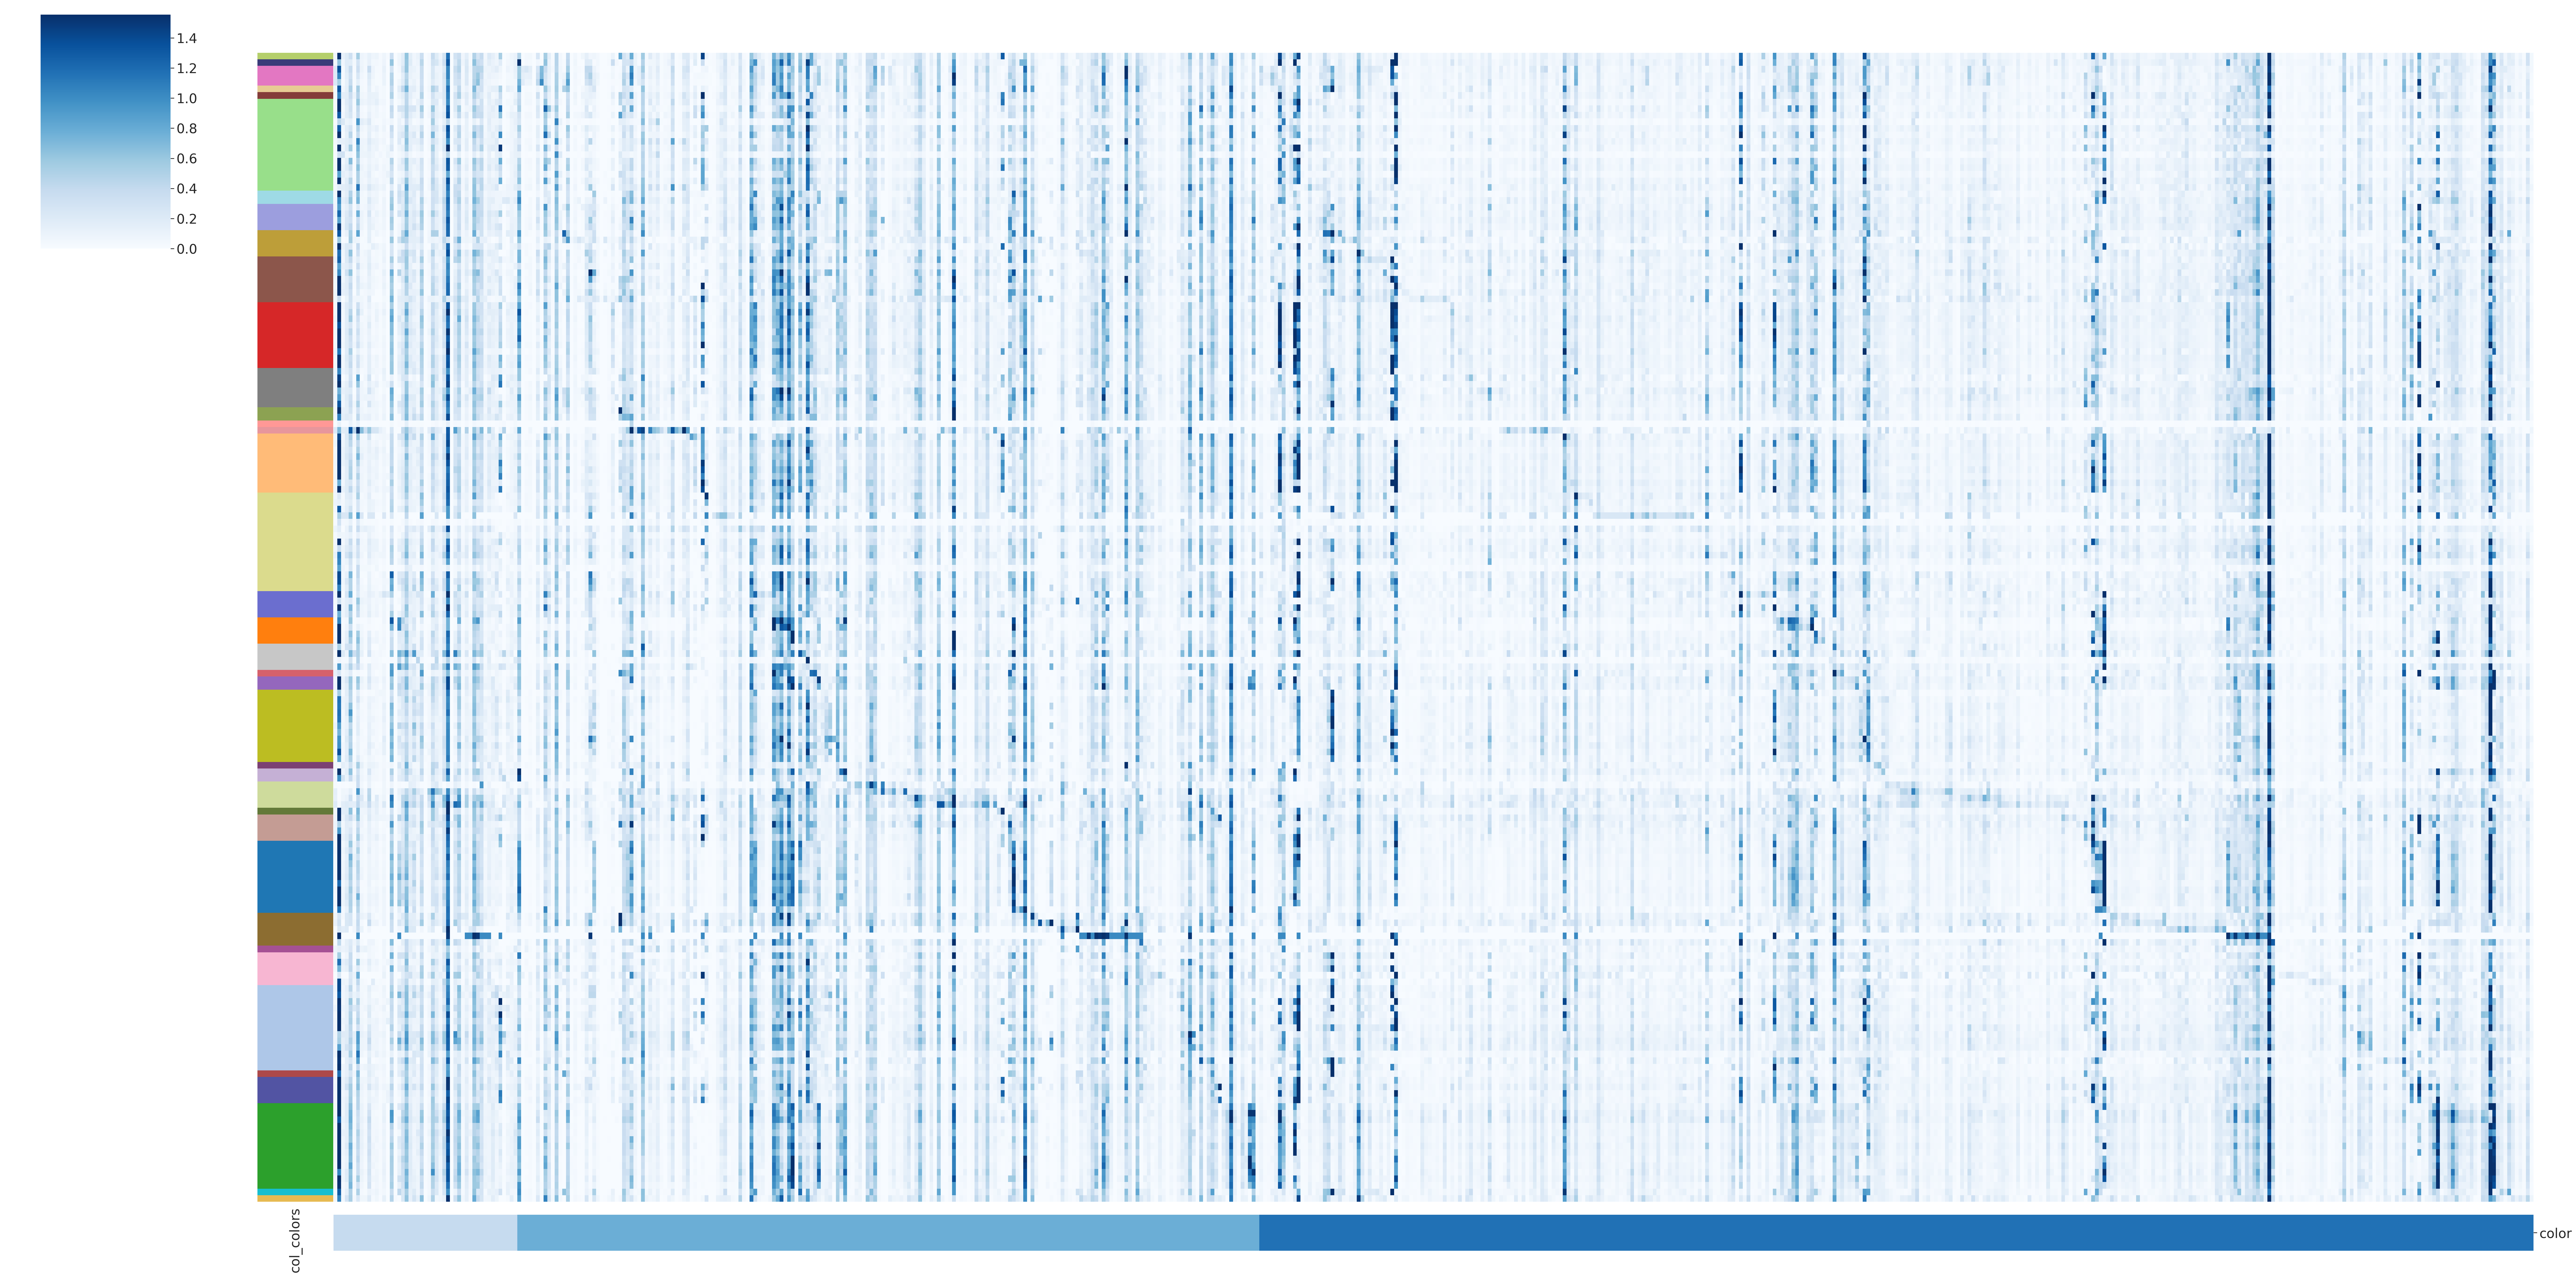

In [35]:
#genrate low rez, all gene Heat Map
# clipped at 1.0

sns.set(font_scale=2)
g = sns.clustermap(expr_data_plot.T, 
               row_cluster=False, 
               col_cluster=False,
               #optimal_ordering=True,
               dendrogram_ratio=(.1, .01),  #used to position the color bar
               cmap ='Blues',
               #vmax = 1.0,
               vmax = np.percentile(expr_data_plot, 99.5),
               #vmin = 0.0,
               row_colors = TFcolors.col_colors,
               col_colors = Genecolormapdf.color,
               yticklabels=False,
               xticklabels=False,
               figsize=(60, 30)
           )

# Move col_colors from top to bottom
# Get the current position of the col_colors axis
col_colors_ax = g.ax_col_colors
current_pos = col_colors_ax.get_position()

# Get the heatmap position
heatmap_pos = g.ax_heatmap.get_position()

# Set new position: move to bottom of heatmap
# Format: [left, bottom, width, height]
new_pos = [current_pos.x0, 
           heatmap_pos.y0 - current_pos.height - 0.01,  # Position below heatmap
           current_pos.width, 
           current_pos.height]

col_colors_ax.set_position(new_pos)

plt.savefig(DATA_OUT_DIR + 'SuppFig10_ThreePartChart.pdf')
plt.show()
plt.close()

## Make color key

In [36]:
# copy the color key for the broad cell types into the palette for the key
key_colors = TFcolors[ ['broadct','col_colors']].drop_duplicates()
ct_palette = key_colors.sort_values('broadct')
ct_palette = ct_palette.reset_index()
ct_palette = ct_palette.drop(['index'], axis =1)

#ct_palette.to_csv(DATA_OUT_DIR + "BroadCellTypeColorPalette.csv")
ct_palette

,broadct,col_colors
0,adventitial_cell,#b5cf6b
1,cardiac_endothelial_cell,#393b79
2,ciliated_epithelial_cell,#e377c2
3,conjunctival_epithelial_cell,#e7cb94
4,connective_tissue_cell,#843c39
5,contractile_cell,#98df8a
6,dendritic_cell,#9edae5
7,duct_epithelial_cell,#9c9ede
8,ecto_epithelial_cell,#bd9e39
9,endo_epithelial_cell,#8c564b


In [37]:
# normalize in both directions
def NormTwoWays(exp_input):
    # copy the data 
    df_min_max_scaled = exp_input.copy() 
    
    # apply normalization techniques in one direction.
    for column in df_min_max_scaled.columns: 
        df_min_max_scaled[column] = (df_min_max_scaled[column] - df_min_max_scaled[column].min()) / (df_min_max_scaled[column].max() - df_min_max_scaled[column].min())  

    # copy the data again but flip
    df_min_max_scaled_flip = df_min_max_scaled.T.copy() 

    # apply normalization techniques in other direction.
    for column in df_min_max_scaled_flip.columns: 
        df_min_max_scaled_flip[column] = (df_min_max_scaled_flip[column] - df_min_max_scaled_flip[column].min()) / (df_min_max_scaled_flip[column].max() - df_min_max_scaled_flip[column].min()) 

    # unflip
    normalized_expr_data_plot = df_min_max_scaled_flip.T.copy()
    return(normalized_expr_data_plot)
    

In [38]:
# normalize in cell type direction
def NormOneWay(exp_input):
    # copy the data 
    df_min_max_scaled = exp_input.copy().T
    
    # apply normalization techniques in one direction.
    for column in df_min_max_scaled.columns: 
        df_min_max_scaled[column] = (df_min_max_scaled[column] - df_min_max_scaled[column].min()) / (df_min_max_scaled[column].max() - df_min_max_scaled[column].min())  

   
    return(df_min_max_scaled.T)

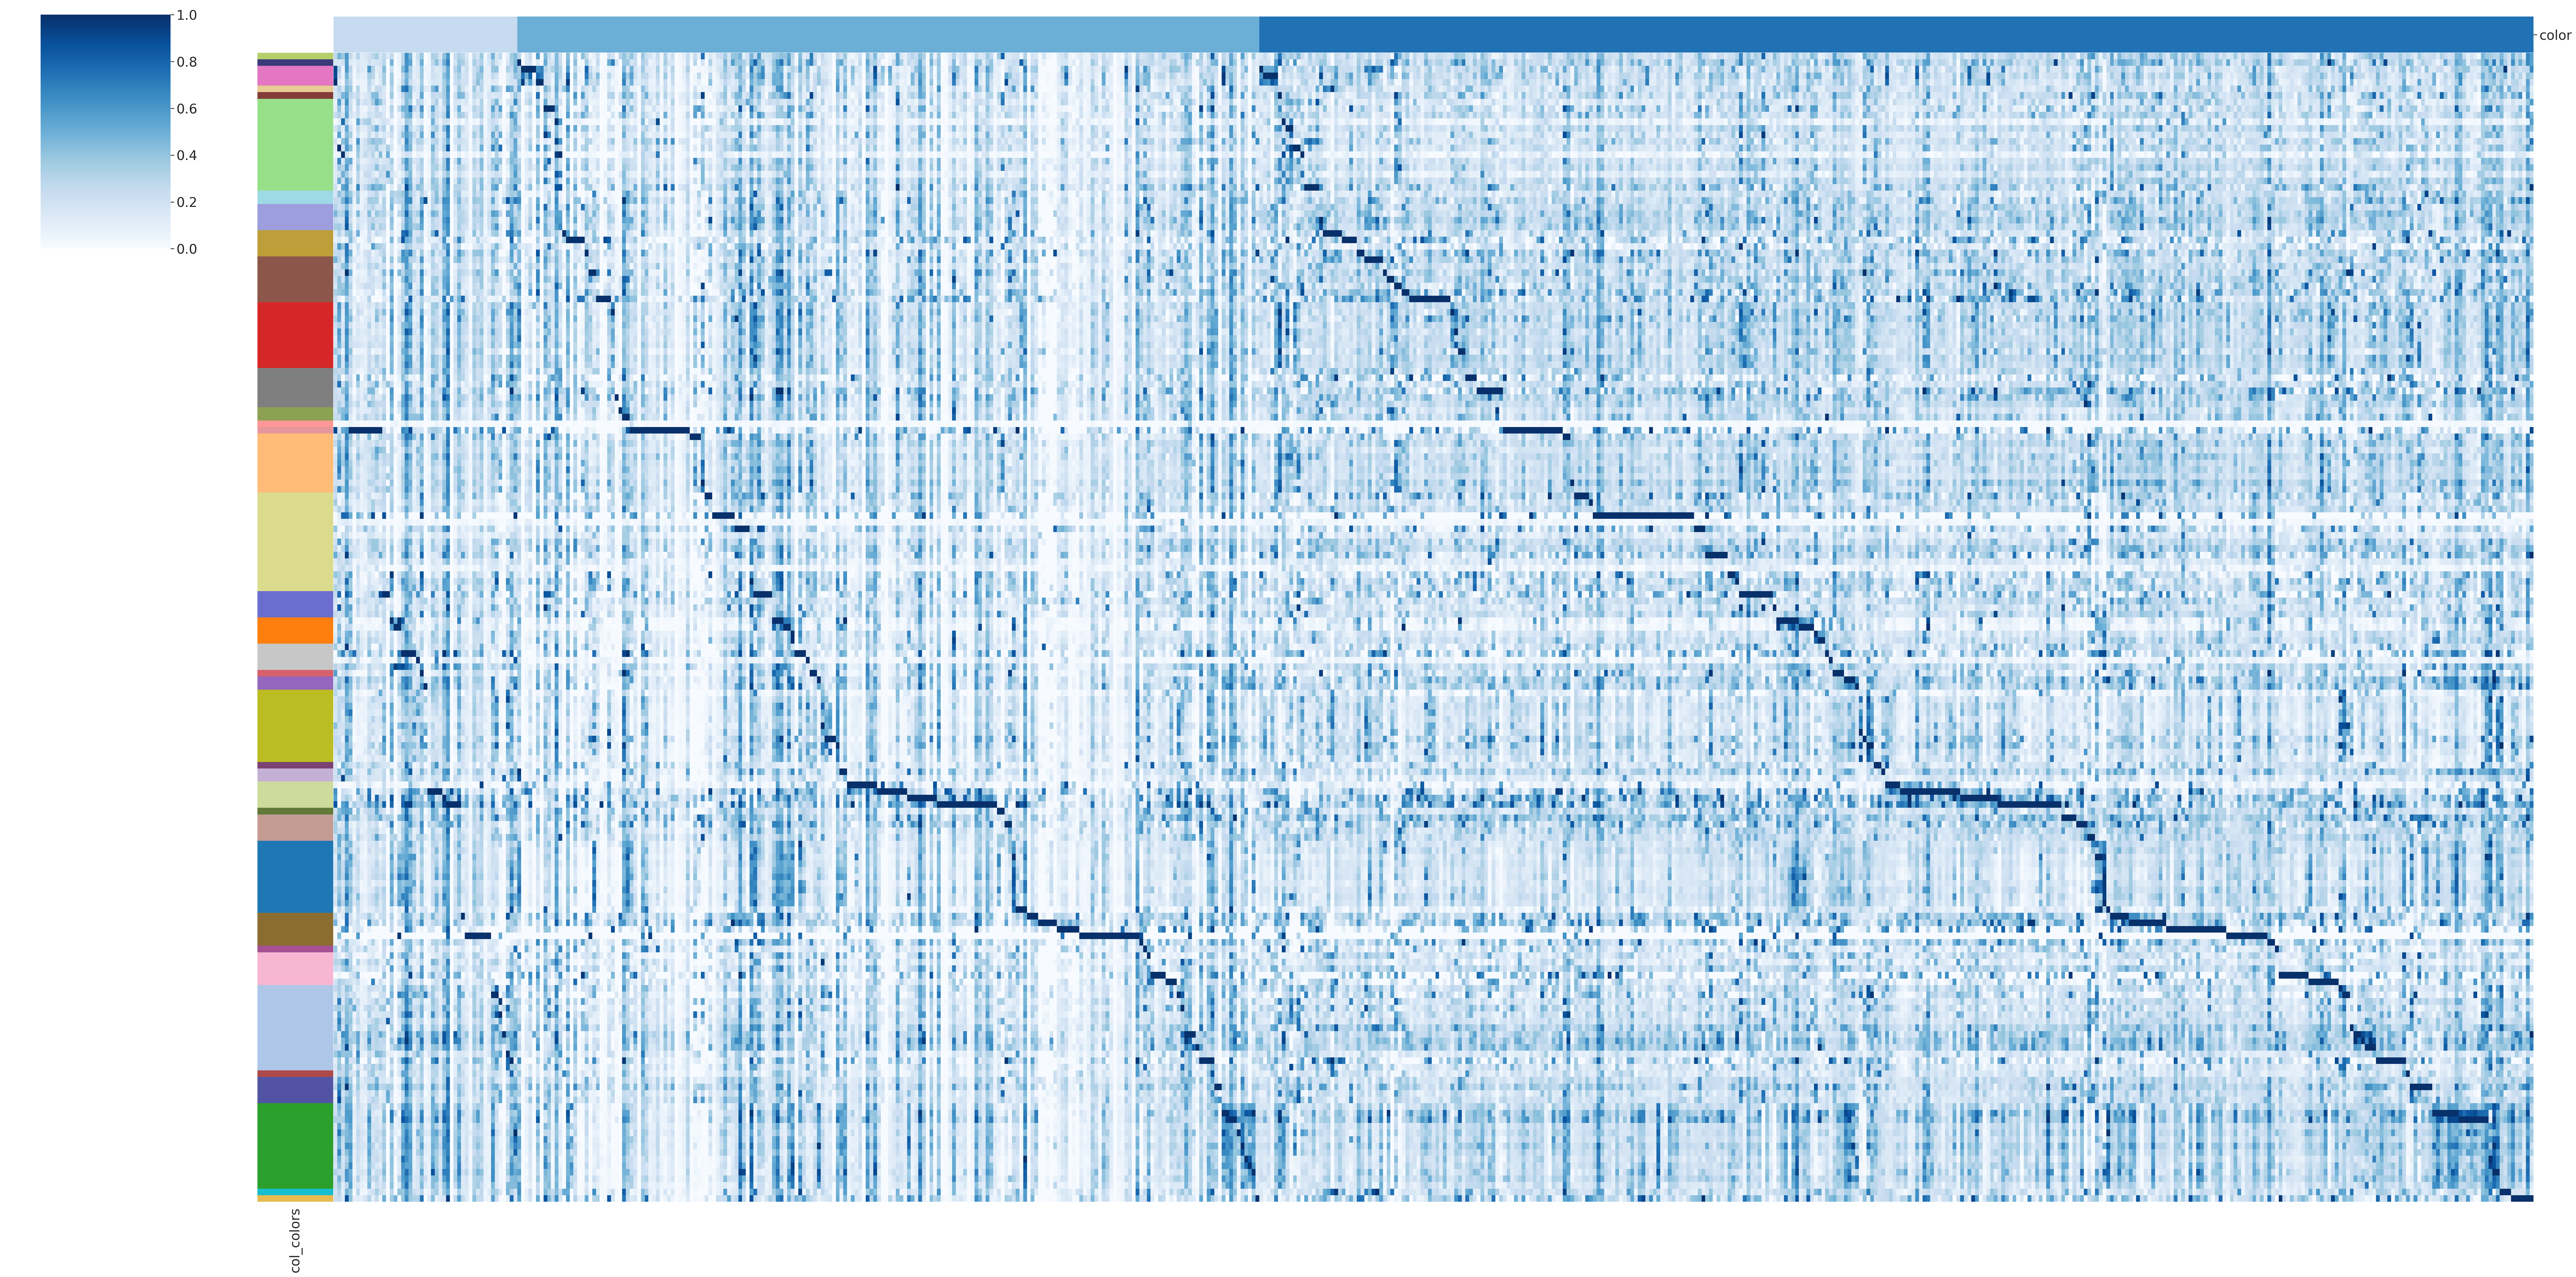

In [40]:
#normalized_expr_data_plot = NormTwoWays(expr_data_plot)
normalized_expr_data_plot = NormOneWay(expr_data_plot)
########### Dont Normalize #############
#normalized_expr_data_plot = expr_data_plot
########################################

#genrate low rez, all gene Heat Map
# this one is two-axis normalized and clipped at 1.0
sns.set(font_scale=2)
sns.clustermap(normalized_expr_data_plot.T, 
               row_cluster=False, 
               col_cluster=False,
               #optimal_ordering=True,
               dendrogram_ratio=(.1, .01),  #used to position the color bar
               cmap ='Blues',
               vmax = 1.0,
               #vmin = 0.0,
               row_colors = TFcolors.col_colors,
               col_colors = Genecolormapdf.color,
               yticklabels=False,
               xticklabels=False,
               figsize=(60, 30)
           )

plt.show()
plt.close()
